In [1]:
# Comprobar la tabla meteorológica
meteo = spark.table("fact_meteo")

print("Registros:", meteo.count())
meteo.printSchema()
display(meteo.limit(10))

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 3, Finished, Available, Finished, False)

Registros: 150607
root
 |-- id_tiempo: integer (nullable = false)
 |-- id_estacion: string (nullable = false)
 |-- temperatura: double (nullable = true)
 |-- humedad_relativa: double (nullable = true)
 |-- velocidad_viento: double (nullable = true)
 |-- direccion_viento: double (nullable = true)
 |-- precipitacion: double (nullable = true)
 |-- presion: double (nullable = true)
 |-- radiacion_solar: double (nullable = true)



SynapseWidget(Synapse.DataFrame, 070ae8be-e354-4b6c-9e9e-8434d677d406)

In [2]:
from pyspark.sql import functions as F

# Cargar tablas
estaciones = spark.table("dim_estacion")
tiempo = spark.table("dim_tiempo")

# Variables meteorológicas
variables = ["temperatura", "humedad_relativa", "velocidad_viento",
             "direccion_viento", "precipitacion", "presion", "radiacion_solar"]

# Disponibilidad por estación
resumen_meteo = (
    meteo.join(estaciones.select("id_estacion", "nombre_estacion"), "id_estacion", "left")
    .groupBy("id_estacion", "nombre_estacion")
    .agg(F.count("*").alias("registros"),
         *[F.count(v).alias(v + "_validos") for v in variables])
    .orderBy("id_estacion")
)

display(resumen_meteo)

# Disponibilidad por año
resumen_anios = (
    meteo.join(tiempo.select("id_tiempo", "anio"), "id_tiempo", "left")
    .groupBy("anio")
    .agg(F.count("*").alias("registros"))
    .orderBy("anio")
)

display(resumen_anios)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 4, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, d9003c45-de37-4e5f-8dee-8bcfde3d9d44)

SynapseWidget(Synapse.DataFrame, e333d3ac-6ca8-4f65-8493-aff708263e2a)

In [3]:
# Estaciones meteorológicas
ids_meteo = meteo.select("id_estacion").distinct()

estaciones_meteo = (
    ids_meteo.join(estaciones, "id_estacion", "left")
    .select("id_estacion", "nombre_estacion", "latitud", "longitud")
)

print("ESTACIONES METEOROLÓGICAS")
display(estaciones_meteo)

# Estaciones de calidad del aire
ids_aire = spark.table("fact_aire").select("id_estacion").distinct()

estaciones_aire = (
    ids_aire.join(estaciones, "id_estacion", "left")
    .select("id_estacion", "nombre_estacion", "latitud", "longitud")
)

print("ESTACIONES DE CALIDAD DEL AIRE")
display(estaciones_aire)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 5, Finished, Available, Finished, False)

ESTACIONES METEOROLÓGICAS


SynapseWidget(Synapse.DataFrame, 2a973e8b-fb9e-4a9a-94a4-000116f5c3da)

ESTACIONES DE CALIDAD DEL AIRE


SynapseWidget(Synapse.DataFrame, 17ebbc50-a1e8-4890-883a-4b85b6001fa5)

In [4]:
# Cargar las tablas
aire = spark.table("fact_aire")
meteo = spark.table("fact_meteo")
contaminantes = spark.table("dim_contaminante")
tiempo = spark.table("dim_tiempo")

# Estaciones presentes en ambos conjuntos de datos
ids_aire = aire.select("id_estacion").distinct()
ids_meteo = meteo.select("id_estacion").distinct()

print("ESTACIONES PRESENTES EN AMBOS DATASETS")
display(ids_aire.join(ids_meteo, "id_estacion", "inner"))

# Cruzar mediciones de la misma estación y hora
coincidencias = (
    aire.join(meteo, ["id_estacion", "id_tiempo"], "inner")
    .join(contaminantes.select("id_contaminante", "nombre"), "id_contaminante", "inner")
    .join(tiempo.select("id_tiempo", "anio"), "id_tiempo", "inner")
)

# Resumen de coincidencias
resumen_coincidencias = (
    coincidencias.groupBy("id_estacion", "anio", "nombre")
    .agg(
        F.count("*").alias("observaciones"),
        F.count("velocidad_viento").alias("viento_validos"),
        F.count("temperatura").alias("temperatura_validos")
    )
    .orderBy("id_estacion", "anio", "nombre")
)

print("COINCIDENCIAS TEMPORALES")
display(resumen_coincidencias)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 6, Finished, Available, Finished, False)

ESTACIONES PRESENTES EN AMBOS DATASETS


SynapseWidget(Synapse.DataFrame, bc805691-51be-4798-aa1b-953a9248b58f)

COINCIDENCIAS TEMPORALES


SynapseWidget(Synapse.DataFrame, 9eb786f2-b71e-46bd-b74f-954cd8068859)

In [5]:
# Seleccionar mediciones válidas de viento y contaminación
datos_viento = (
    coincidencias.dropna(subset=["velocidad_viento", "concentracion"])
    .select("anio", "nombre", "id_tiempo", "concentracion", "velocidad_viento")
)

# Calcular la correlación de Pearson por contaminante
pearson_viento = (
    datos_viento.groupBy("nombre")
    .agg(
        F.count("*").alias("observaciones"),
        F.round(F.corr("velocidad_viento", "concentracion"), 3).alias("pearson")
    )
    .orderBy("nombre")
)

display(pearson_viento)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 7, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 511532cf-5c16-4f6d-8c1f-6a36f1e244aa)

In [6]:
import pandas as pd

# Convertir las observaciones a Pandas
pdf_viento = datos_viento.select(
    "anio", "nombre", "velocidad_viento", "concentracion"
).toPandas()

# Función para calcular las correlaciones
def calcular_corr(grupo):
    return pd.Series({
        "observaciones": len(grupo),
        "pearson": grupo["velocidad_viento"].corr(grupo["concentracion"], method="pearson"),
        "spearman": grupo["velocidad_viento"].corr(grupo["concentracion"], method="spearman")
    })

# Correlaciones globales
correlaciones_globales = (
    pdf_viento.groupby("nombre").apply(calcular_corr)
    .reset_index().rename(columns={"nombre": "contaminante"}).round(3)
)

print("CORRELACIONES GLOBALES")
display(correlaciones_globales)

# Correlaciones por año
correlaciones_anuales = (
    pdf_viento.groupby(["anio", "nombre"]).apply(calcular_corr)
    .reset_index().rename(columns={"nombre": "contaminante"})
    .sort_values(["anio", "contaminante"]).round(3)
)

print("CORRELACIONES POR AÑO")
display(correlaciones_anuales)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 8, Finished, Available, Finished, False)

CORRELACIONES GLOBALES


SynapseWidget(Synapse.DataFrame, 08b175a5-84fb-4356-8278-acb233ab9691)

CORRELACIONES POR AÑO


SynapseWidget(Synapse.DataFrame, 4ea8dbef-9005-4cec-842a-bb799a706db4)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 14, Finished, Available, Finished, False)

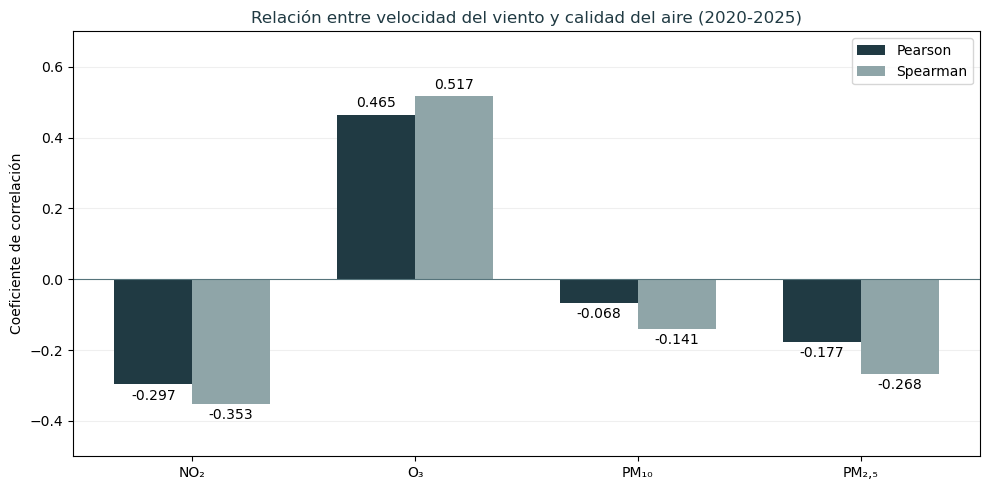

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import os

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Preparar los datos
datos = correlaciones_globales.set_index("contaminante").loc[["NO2", "O3", "PM10", "PM2.5"]]
x = np.arange(len(datos))
ancho = 0.35

# Crear gráfico
fig, ax = plt.subplots(figsize=(10, 5))

barras1 = ax.bar(x - ancho/2, datos["pearson"], ancho,
                 color="#203A43", label="Pearson")

barras2 = ax.bar(x + ancho/2, datos["spearman"], ancho,
                 color="#8FA5A8", label="Spearman")

ax.axhline(0, color="#56747B", linewidth=0.8)
ax.set_xticks(x)
ax.set_xticklabels(["NO₂", "O₃", "PM₁₀", "PM₂,₅"])
ax.set_ylabel("Coeficiente de correlación")
ax.set_title("Relación entre velocidad del viento y calidad del aire (2020-2025)",
             color="#203A43")

# Mostrar los valores
ax.bar_label(barras1, fmt="%.3f", padding=3)
ax.bar_label(barras2, fmt="%.3f", padding=3)

ax.set_ylim(-0.5, 0.7)
ax.legend()
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()

# Guardar PNG
plt.savefig(f"{ruta}/07_correlacion_viento_calidad_aire_2020_2025.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [8]:
# Variables meteorológicas
variables = ["temperatura", "humedad_relativa", "velocidad_viento",
             "precipitacion", "presion", "radiacion_solar"]

# Seleccionar las dos estaciones meteorológicas
meteo_ampliada = (
    meteo.filter(F.col("id_estacion").isin("46250049", "46250900"))
    .join(tiempo.select("id_tiempo", "anio"), "id_tiempo", "inner")
    .join(estaciones.select("id_estacion", "nombre_estacion"), "id_estacion", "left")
)

# Disponibilidad por estación y año
resumen_variables = (
    meteo_ampliada.groupBy("anio", "nombre_estacion")
    .agg(
        F.count("*").alias("registros"),
        *[F.count(v).alias(v + "_validos") for v in variables]
    )
    .orderBy("anio", "nombre_estacion")
)

display(resumen_variables)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 16, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 89c50895-dc14-45a5-a90c-6bbcb3be528a)

In [9]:
# Calcular el porcentaje de datos válidos por variable y estación
resumen_porcentajes = resumen_variables.select(
    "anio", "nombre_estacion",
    *[
        F.round(F.col(v + "_validos") / F.col("registros") * 100, 1).alias(v + "_pct")
        for v in variables
    ]
)

display(resumen_porcentajes)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 17, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 195410a0-c6ee-4ec2-b5d2-92ff99ff6f4f)

In [10]:
# Seleccionar fechas de 2020 a 2025
fechas = tiempo.filter(F.col("anio").between(2020, 2025)).select("id_tiempo", "fecha")

# Media diaria por estación de calidad del aire
aire_estacion_diario = (
    aire.join(fechas, "id_tiempo", "inner")
    .join(contaminantes.select("id_contaminante", "nombre"), "id_contaminante", "inner")
    .filter(F.col("concentracion").isNotNull())
    .groupBy("fecha", "id_estacion", "nombre")
    .agg(
        F.avg("concentracion").alias("concentracion_estacion"),
        F.countDistinct("id_tiempo").alias("horas_aire")
    )
    .filter(F.col("horas_aire") >= 18)
)

# Media diaria de las estaciones de aire disponibles
aire_diario = (
    aire_estacion_diario.groupBy("fecha", "nombre")
    .agg(
        F.avg("concentracion_estacion").alias("concentracion_media"),
        F.countDistinct("id_estacion").alias("n_estaciones_aire")
    )
)

# Agregación diaria de las estaciones meteorológicas
meteo_diario = (
    meteo.filter(F.col("id_estacion").isin("46250049", "46250900"))
    .join(fechas, "id_tiempo", "inner")
    .groupBy("fecha", "id_estacion")
    .agg(
        F.avg("temperatura").alias("temperatura"),
        F.avg("humedad_relativa").alias("humedad_relativa"),
        F.avg("velocidad_viento").alias("velocidad_viento"),
        F.sum("precipitacion").alias("precipitacion"),
        F.avg("presion").alias("presion"),
        F.avg("radiacion_solar").alias("radiacion_solar"),
        F.countDistinct("id_tiempo").alias("horas_meteo")
    )
    .filter(F.col("horas_meteo") >= 18)
)

# Integrar aire y meteorología por fecha
datos_meteo_aire = (
    aire_diario.join(meteo_diario, "fecha", "inner")
    .orderBy("fecha", "id_estacion", "nombre")
)

print("Observaciones integradas:", datos_meteo_aire.count())
display(datos_meteo_aire.limit(20))

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 18, Finished, Available, Finished, False)

Observaciones integradas: 16387


SynapseWidget(Synapse.DataFrame, 9fa18416-8d64-4c3c-ad61-780ff2d2c0fb)

In [11]:
# Variables meteorológicas
variables_meteo = ["temperatura", "humedad_relativa", "velocidad_viento",
                   "precipitacion", "presion", "radiacion_solar"]

# Comprobar la disponibilidad de los datos integrados
resumen_integracion_meteo = (
    datos_meteo_aire.withColumn("anio", F.year("fecha"))
    .groupBy("anio", "id_estacion", "nombre")
    .agg(
        F.countDistinct("fecha").alias("dias"),
        F.min("n_estaciones_aire").alias("min_estaciones_aire"),
        F.max("n_estaciones_aire").alias("max_estaciones_aire"),
        *[F.count(v).alias(v + "_validos") for v in variables_meteo]
    )
    .orderBy("anio", "id_estacion", "nombre")
)

display(resumen_integracion_meteo)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 19, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 80968cf6-8c88-4766-be25-525cc3d1be7a)

In [12]:
# Preparar los datos de las variables meteorológicas
datos_largos = None

for variable in variables_meteo:
    bloque = (
        datos_meteo_aire
        .select("fecha", "id_estacion", "nombre", "concentracion_media",
                F.lit(variable).alias("variable_meteo"),
                F.col(variable).alias("valor_meteo"))
        .dropna(subset=["concentracion_media", "valor_meteo"])
    )

    datos_largos = bloque if datos_largos is None else datos_largos.unionByName(bloque)

# Calcular correlaciones de Pearson
correlaciones_meteo = (
    datos_largos.groupBy("id_estacion", "nombre", "variable_meteo")
    .agg(
        F.count("*").alias("observaciones"),
        F.round(F.corr("valor_meteo", "concentracion_media"), 3).alias("pearson")
    )
    .orderBy("id_estacion", "nombre", "variable_meteo")
)

print("CORRELACIONES METEOROLOGÍA - AIRE")
display(correlaciones_meteo)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 20, Finished, Available, Finished, False)

CORRELACIONES METEOROLOGÍA - AIRE


SynapseWidget(Synapse.DataFrame, 3a2a9b5c-dfc2-4835-aa25-0052be45bcff)

In [13]:
import pandas as pd

# Convertir los datos a Pandas
pdf_meteo = datos_largos.select(
    "id_estacion", "nombre", "variable_meteo",
    "valor_meteo", "concentracion_media"
).toPandas()

# Calcular Spearman por estación, contaminante y variable
spearman_meteo = (
    pdf_meteo.groupby(["id_estacion", "nombre", "variable_meteo"])
    .apply(lambda d: d["valor_meteo"].corr(d["concentracion_media"], method="spearman"))
    .reset_index(name="spearman")
)

# Combinar Pearson y Spearman
pearson_pdf = correlaciones_meteo.toPandas()

correlaciones_completas = (
    pearson_pdf.merge(spearman_meteo, on=["id_estacion", "nombre", "variable_meteo"])
    .round(3)
    .sort_values(["id_estacion", "nombre", "variable_meteo"])
)

display(correlaciones_completas)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 21, Finished, Available, Finished, False)

/tmp/ipykernel_5598/3447438186.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d["valor_meteo"].corr(d["concentracion_media"], method="spearman"))


SynapseWidget(Synapse.DataFrame, cdd3cc89-4414-4fa7-9e82-b91ee99f524a)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 44, Finished, Available, Finished, False)

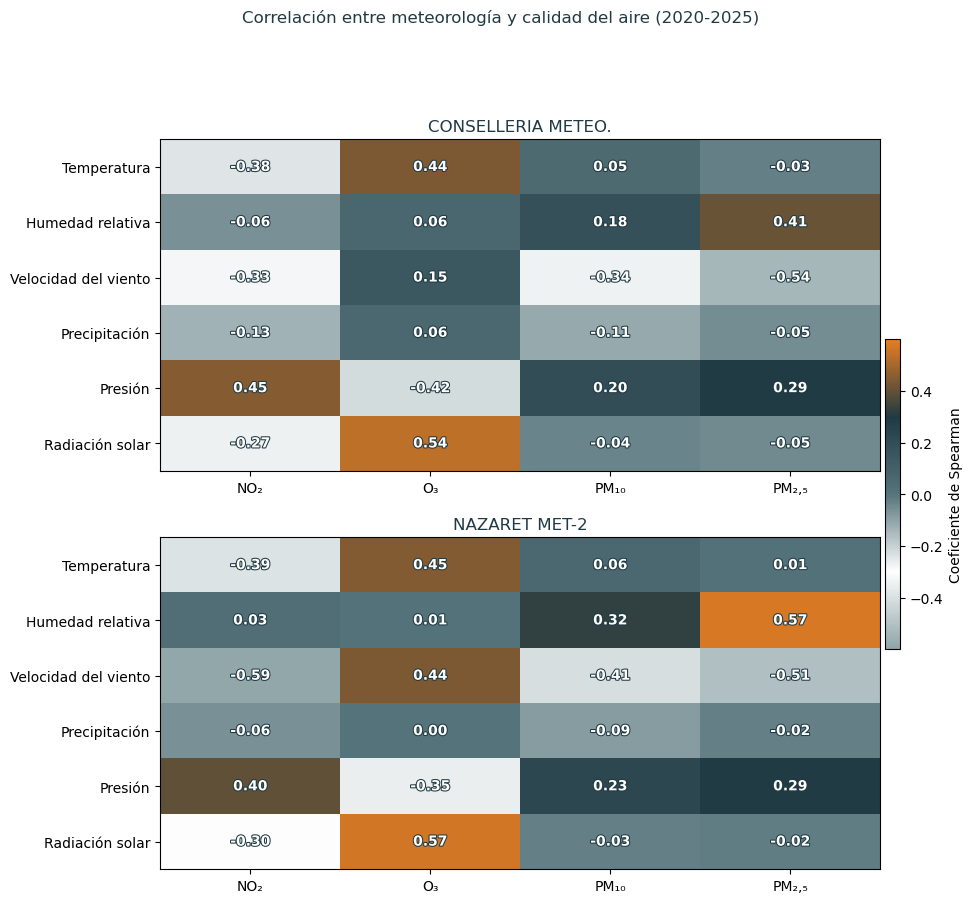

In [16]:
import matplotlib.pyplot as plt
import pandas as pd
import os
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

# Carpeta de salida
ruta = "/lakehouse/default/Files/export_graficos"
os.makedirs(ruta, exist_ok=True)

# Estaciones y variables
estaciones = {"46250049": "CONSELLERIA METEO.", "46250900": "NAZARET MET-2"}
variables = ["temperatura", "humedad_relativa", "velocidad_viento",
             "precipitacion", "presion", "radiacion_solar"]
etiquetas = ["Temperatura", "Humedad relativa", "Velocidad del viento",
             "Precipitación", "Presión", "Radiación solar"]

# Paleta de colores del TFM
colores = ["#8FA5A8", "#FFFFFF", "#56747B", "#203A43", "#E67E22"]
cmap = LinearSegmentedColormap.from_list("paleta_tfm", colores)
cmap.set_bad("white")

# Crear los dos mapas de calor
fig, ejes = plt.subplots(2, 1, figsize=(10, 10))

for eje, (id_estacion, nombre) in zip(ejes, estaciones.items()):
    datos = correlaciones_completas[
        correlaciones_completas["id_estacion"].astype(str) == id_estacion
    ]

    matriz = datos.pivot(index="variable_meteo", columns="nombre", values="spearman")
    matriz = matriz.reindex(index=variables, columns=["NO2", "O3", "PM10", "PM2.5"])

    imagen = eje.imshow(matriz.values, cmap=cmap,
                        norm=TwoSlopeNorm(vmin=-0.6, vcenter=0, vmax=0.6),
                        aspect="auto")

    eje.set_xticks(range(4), ["NO₂", "O₃", "PM₁₀", "PM₂,₅"])
    eje.set_yticks(range(6), etiquetas)
    eje.set_title(nombre, color="#203A43")

    # Mostrar los coeficientes
    for i in range(6):
        for j in range(4):
            valor = matriz.iloc[i, j]
            if pd.notna(valor):
                eje.text(j, i, f"{valor:.2f}", ha="center", va="center",
                         color="white", fontweight="bold",
                         path_effects=[pe.withStroke(linewidth=1.5, foreground="#203A43")])

# Barra de colores común
fig.colorbar(imagen, ax=ejes, label="Coeficiente de Spearman",
             fraction=0.02, pad=0.06)

fig.suptitle("Correlación entre meteorología y calidad del aire (2020-2025)",
             color="#203A43")

fig.subplots_adjust(left=0.16, right=0.88, bottom=0.12, top=0.85, wspace=0.65)

# Guardar solo PNG
plt.savefig(f"{ruta}/08_heatmap_meteorologia_calidad_aire_2020_2025.png",
            dpi=300, bbox_inches="tight")

plt.show()

In [17]:
# Relaciones meteorológicas seleccionadas
relaciones = [
    ("NO2", "velocidad_viento"),
    ("O3", "radiacion_solar"),
    ("PM2.5", "humedad_relativa"),
    ("PM2.5", "velocidad_viento")
]

# Incorporar el año
datos_anuales = datos_largos.withColumn("anio", F.year("fecha"))

# Filtrar las relaciones seleccionadas
condicion = None
for cont, variable in relaciones:
    filtro = (F.col("nombre") == cont) & (F.col("variable_meteo") == variable)
    condicion = filtro if condicion is None else condicion | filtro

datos_seleccionados = datos_anuales.filter(condicion)

# Calcular correlaciones anuales de Pearson
correlaciones_anuales_meteo = (
    datos_seleccionados.groupBy("anio", "id_estacion", "nombre", "variable_meteo")
    .agg(
        F.count("*").alias("observaciones"),
        F.round(F.corr("valor_meteo", "concentracion_media"), 3).alias("pearson")
    )
    .orderBy("id_estacion", "nombre", "variable_meteo", "anio")
)

display(correlaciones_anuales_meteo)

StatementMeta(, 2311380f-e14e-48d9-8692-e4893854170f, 46, Finished, Available, Finished, False)

SynapseWidget(Synapse.DataFrame, 29f80113-ed18-4e49-b355-dbdf85bd4237)